# The significant SV insertions: what they carry, and what each one is

The gene layers under `genes/` ask of every GEA/GWAS hit: **does it disrupt or flank a TAIR10 gene?**
For a *deletion* that is the whole question -- its content is TAIR10 sequence. For an *insertion* it
is half the question: the inserted sequence is absent from TAIR10, so an insertion with no gene handle
at its site could still carry a gene copy, a transposable element, or sequence new to the species.

This notebook takes the **193 SV insertions among the 3,019 pooled GEA+GWAS hits** (181 GEA, 12
GWAS-only) and answers both halves:

- **Sections 1-5 -- is what they carry unusual?** Each hit is compared with the ~10.7k insertions
  common enough to have been tested, on content class, raw descriptions, landing site and position.
- **Sections 6-12 -- what is each one?** Locus by locus: the identity of the inserted sequence, the
  consequence at its landing site (every transcript), the gene's function, and how well the panel
  supports the call.

## The three descriptions of an insertion, and the class built from them

| source | question it answers |
|---|---|
| **BLAST class** (dc-megablast vs TAIR10: `te_derived` + family / `gene_dup` / `local_dup` / `dispersed_dup` / `novel`) | where else in Col-0 does this sequence occur, and what is annotated there? |
| **carrier-assembly annotation** (the insertion lifted back into an assembly that carries it: Helixer genes, Liftoff-projected Col-0 genes, TRASH satellites, repeat compartments) | what is annotated where this sequence actually sits? |
| **the TAIR10 flank** (blastn vs +/-5 kb around the site) | is it simply one more copy of the sequence beside it? |

A **fourth** description, hits only, comes from `build_sv_hit_annotation.py`: six layers run directly
on the inserted sequence -- RepeatMasker against a library built from TAIR10's own 31,189 annotated
elements, structural signatures at the insertion point in the carrier, mmseqs recurrence against all
172k panel insertions, blastx against the UniProt proteome, the landing site in the carrier's own gene
models, and Tandem Repeat Finder. These are **annotation only**: they add `repeat_family`, divergence,
recurrence and the `LAYERS:` line on each card, and they never move a locus between content classes.
Section 6 reports what each layer does and does not deliver.

`content_class` (rules in `sv_content.py`, computed in `build_sv_cargo.py` for hits and background
alike) combines the first three using each only where it speaks to **content**. Two rules matter for
reading it:

- **Gene-BODY overlap in the carrier is not cargo evidence.** A 55 bp insertion with no Col-0 match
  sitting in an intron is "100% inside a Helixer gene" because the gene spans the intron -- that is
  where it landed, not what it carries. Only **CDS** coverage counts as coding content.
- **Overlaps are bp-level, not any-contact**, and taken from the best record of each locus: 31 of the
  193 loci have an annotation flag set by an overlap covering < 20% of the insertion.

## Per-locus detail (sections 6-12), from `build_sv_hit_dossier.py`

The sequence itself (GC, dustmasker low-complexity, tandem period), its Col-0 homologs genome-wide
(TE family and superfamily from `TAIR10_Transposable_Elements.txt`), the carrier assembly at bp level,
and the TAIR10 landing site **for every transcript of every gene the changed span touches** -- for
coding changes the full mutant protein, for introns the distance to the splice site -- plus gene
function from TAIR GO + UniProt.

## Two facts about the panel that the join depends on (verified in `build_sv_cargo.py`)

1. **One insertion is usually several arch3 records.** At a hit position the panel carries a median 3
   (max 29) records with identical `(pos, ref_len, alt_len)` but *different* ALT sequences -- the same
   insertion on different founder haplotypes, split by internal SNPs, each carried by a disjoint founder
   subset. One row per locus is used throughout (majority BLAST class, best-record evidence); the 5 loci
   whose records disagree are listed in section 5.
2. **`af_store/index_nonsnp` is exactly the panel's non-SNP records in panel order**, so a record ordinal
   maps to one af_store row with no four-field-key ambiguity.

## What "background" means here

The GEA ran at MAF > 0.05 per record, so the comparison set is every insertion locus with at least one
record at minor-allele frequency >= 0.05 -- **~10,700 "eligible" loci** (exact count printed below; it
includes the hits that pass the cut) -- collapsed the same way as the hits. The rare insertions (57.5%
are private to one founder) are deliberately not the comparator: they are larger (median ~1.1 kb vs
~230 bp) and more TE-rich, and could never have been hits.

In [1]:
import os, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({'figure.dpi':110,'font.size':8,'axes.linewidth':0.6})
pd.set_option("display.width", 320); pd.set_option("display.max_colwidth", 400); pd.set_option("display.max_rows", 400)

GEA = os.path.abspath(".."); R = f"{GEA}/genes/convergence/results"
K4 = ["chrom","pos","ref_len","alt_len"]
# approximate TAIR10 centromere midpoints (Mb); pericentromere = within 2.5 Mb
CEN = {"Chr1":15.086,"Chr2":3.607,"Chr3":13.587,"Chr4":3.956,"Chr5":11.725}
CHRLEN = {"Chr1":30.43,"Chr2":19.70,"Chr3":23.46,"Chr4":18.59,"Chr5":26.98}
CARGO = ["te_derived","gene_dup","local_dup","dispersed_dup","novel"]          # BLAST class
KCOL = {"te_derived":"#CC79A7","gene_dup":"#D55E00","local_dup":"#E69F00",
        "dispersed_dup":"#009E73","novel":"0.55"}
CONTENT = ["organellar_rDNA_gap","TE","tandem_expansion","satellite","other_gene_seq",
           "carrier_coding","dup_nongenic","unresolved"]                        # content class
CCOL = {"organellar_rDNA_gap":"#F0E442","TE":"#CC79A7","tandem_expansion":"#56B4E9","satellite":"#0072B2",
        "other_gene_seq":"#D55E00","carrier_coding":"#E69F00","dup_nongenic":"#009E73","unresolved":"0.55"}
SITES = ["CDS","intron","UTR / ncRNA exon","other genic","promoter (<2 kb)","intergenic","TE gene","pseudogene","TE region","gene desert"]
SCOL = dict(zip(SITES, ["#D55E00","#E69F00","#F0E442","#999933","#009E73","#56B4E9","#CC79A7","#AA4499","#882255","0.6"]))
ZERO = "0.6"

def style(ax, axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.88", lw=0.7, axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)
def note(ax, txt, loc=(0.03,0.93), **kw):
    ax.annotate(txt, xy=loc, xycoords="axes fraction", fontsize=8, color="0.3", **kw)
def pfmt(p): return f"{p:.1e}" if p < 1e-4 else f"{p:.3f}"
def boolcol(df, cols):
    for c in cols:
        if c in df: df[c] = df[c].astype(str).str.lower().eq("true")
    return df

# one row per hit locus: the dossier table already carries every column of sv_hit_cargo.csv
D = pd.read_csv(f"{R}/sv_hit_dossier.csv", keep_default_na=False)
for c in ["size","n_rec","freq_sum","pident","gea_nlp","dist_to_gene","gwas_n_gardens","gc","dust_frac",
          "max_trash","max_flank_adj","max_helixer_cds","max_liftoff_cds","n_called","n_carriers","n_genes_hit"]:
    D[c] = pd.to_numeric(D[c], errors="coerce")
D = boolcol(D, ["gene_handle","helixer_hit","liftoff_hit","trash_hit","repeat_hit","in_gea","in_gwas","carrier_evidence"])
D["cen_dist"] = [abs(p/1e6 - CEN[c]) for c, p in zip(D.chrom, D.pos)]
D["peri"] = D.cen_dist <= 2.5
D["tier"] = D.tier.replace("", "none")
D["test"] = np.where(D.in_gea, "GEA", "GWAS-only")

# the six annotation layers (build_sv_hit_annotation.py), hits only. Added as ANNOTATION: they never
# change content_class. `rec_*` collides -- the dossier's rec_ columns are the per-record GEA replay,
# the layer's are mmseqs recurrence -- so the dossier's copy wins and only new columns are taken.
A = pd.read_csv(f"{R}/sv_hit_annotation_loci.csv", keep_default_na=False)
D = D.merge(A.drop(columns=[c for c in A.columns if c in D.columns and c not in K4]), on=K4, how="left")
for c in ["rm_div","rm_cons_frac","rm_n_frag","rm_q_cov","str_ltr_len","str_tir_len","str_tsd_len","str_polyA",
          "rec_n_loci","rec_n_chrom","rec_n_records","rec_top_id","prot_aa","prot_pident","prot_frac_aa",
          "trf_period","trf_copies","trf_pct_match","trf_span","car_hx_frac","car_hx_cds_frac",
          "car_lo10_frac","car_lo12_frac"]:
    D[c] = pd.to_numeric(D[c], errors="coerce")
D["prot_is_te"] = D.prot_is_te.astype(str).eq("True")
# RepeatMasker emits Simple_repeat / Low_complexity whatever library it is given: those are not TE calls
SIMPLE = "Simple_repeat|Low_complexity|Satellite"
D["rm_is_te"] = D.rm_elem.astype(str).ne("") & ~D.rm_class.astype(str).str.match(SIMPLE)
D["repeat_family"] = np.where(D.rm_is_te, D.rm_family,
                       np.where(D.rm_elem.astype(str).ne(""), "(simple/low-cplx)", ""))
D["rm_div_te"] = D.rm_div.where(D.rm_is_te)   # divergence only means something for a real TE family
D["recurs"] = D.rec_n_loci > 1
MIN_REAL_TSD = 4                             # below this a flanking direct repeat is chance (see s.6)
D["real_tsd"] = D.str_tsd_len >= MIN_REAL_TSD
L = D                                        # the comparison sections read it as `L`

BG = pd.read_csv(f"{R}/sv_insertion_loci_background.csv", keep_default_na=False)
for c in ["size","n_rec","freq_max","maf_max","freq_sum","pident","n_called"]:
    BG[c] = pd.to_numeric(BG[c], errors="coerce")
BG = boolcol(BG, ["helixer_hit","liftoff_hit","trash_hit","repeat_hit"])
BG["cen_dist"] = [abs(p/1e6 - CEN[c]) for c, p in zip(BG.chrom, BG.pos)]
E = BG[BG.maf_max >= 0.05].copy()            # eligible for the MAF>0.05 GEA
assert (E.content_class != "").all(), "eligible loci without a content class -- rerun build_sv_cargo.py"

def site_cat(r):
    if str(r.site_feature).startswith("CDS"): return "CDS"
    if r.site_gene_type == "TE_gene": return "TE gene"
    if r.site_gene_type == "pseudogene": return "pseudogene"
    if r.site_feature in ("5'UTR","3'UTR","exon(non-coding)"): return "UTR / ncRNA exon"
    if "intron" in str(r.site_feature) or r.site_feature == "splice-region": return "intron"
    if r.site_feature: return "other genic"
    return {"3_promoter":"promoter (<2 kb)","6_TE":"TE region","7_proximal_intergenic":"intergenic",
            "8_gene_desert":"gene desert"}.get(r.tier, "intergenic")
D["site_cat"] = [site_cat(r) for r in D.itertuples()]

def cards(df, extra=()):
    """One block per locus: what it IS, what it DOES, its support, and any caveats."""
    for r in df.sort_values("gea_nlp", ascending=False, na_position="last").itertuples():
        nlp = f"GEA -log10p {r.gea_nlp:.1f} ({r.gea_best_axis})" if np.isfinite(r.gea_nlp) else f"GWAS-only, {r.gwas_n_gardens:.0f} gardens"
        print(f"{r.chrom}:{r.pos:,}   {nlp}   insertion freq {r.freq_sum:.2f}   {r.n_rec:.0f} records   "
              f"{r.n_carriers:.0f} carrier genomes, called in {r.n_called:.0f}/231")
        print(f"   IS    : {r.identity}")
        print(f"   DOES  : {r.consequence}")
        if isinstance(r.annotation, str) and r.annotation and r.annotation != "no signal from any layer":
            print(f"   LAYERS: {r.annotation}")
        for e in extra:
            v = getattr(r, e)
            if v not in ("", None) and not (isinstance(v, float) and np.isnan(v)): print(f"   {e:6}: {v}")
        if r.caveats: print(f"   NOTE  : {r.caveats}")
        print()

print(f"hit insertion loci: {len(D)}  (GEA {int(D.in_gea.sum())}, GWAS-only {int((~D.in_gea).sum())}; "
      f"{int(D.gene_handle.sum())} with a gene handle at the site, {int((~D.gene_handle).sum())} without)")
print(f"records per hit locus: median {D.n_rec.median():.0f}, max {D.n_rec.max():.0f}; "
      f"BLAST class disagrees across split records at {int((D.n_cls.astype(int)>1).sum())} loci")
print(f"all insertion loci: {len(BG):,}   eligible (any record MAF>=0.05): {len(E):,} "
      f"(of which {int(E.set_index(K4).index.isin(D.set_index(K4).index).sum())} are hits; "
      f"{int((~D.set_index(K4).index.isin(E.set_index(K4).index)).sum())} hits fall below the cut)")
print(f"median size  hits {D['size'].median():,.0f} bp | eligible {E['size'].median():,.0f} | all {BG['size'].median():,.0f}")


hit insertion loci: 193  (GEA 181, GWAS-only 12; 90 with a gene handle at the site, 103 without)
records per hit locus: median 3, max 29; BLAST class disagrees across split records at 5 loci
all insertion loci: 96,094   eligible (any record MAF>=0.05): 10,660 (of which 166 are hits; 27 hits fall below the cut)
median size  hits 275 bp | eligible 232 | all 947


## 1. One content class per insertion, hits vs background

The two systems merged into one label, using each only where section 5 showed it speaks to
**content**. Implemented in `sv_content.py::content_class()` and applied identically to the hits and
to every frequency-eligible background locus; evidence is bp-level and taken from the best record of
each locus; first rule that matches wins.

| content class | rule |
|---|---|
| `organellar_rDNA_gap` | >= 20% of the lifted insertion lies in chloroplast / mitochondria / 5S or 45S rDNA / an N-gap in the carrier assembly. Centromere and telomere do not count -- they are a location (section 3) |
| `TE` | BLAST `te_derived` |
| `tandem_expansion` | >= 50% of the inserted sequence is a copy of TAIR10 sequence within 50 bp of the site (blastn against +/-5 kb) -- one more unit of what is already there |
| `satellite` | >= 50% of the insertion in a TRASH array, and not an adjacent copy |
| `other_gene_seq` | carries sequence of a Col-0 gene other than the one it sits in (the BLAST `gene_dup` target, or a Liftoff gene covering >= 20%), compared by AT-ID |
| `carrier_coding` | no match above, but >= 50% of the insertion is CDS in a carrier gene model |
| `dup_nongenic` | BLAST `local_dup` / `dispersed_dup` |
| `unresolved` | everything else |

Left: hits vs eligible background. Middle: where each BLAST class goes. Right: size by content class.

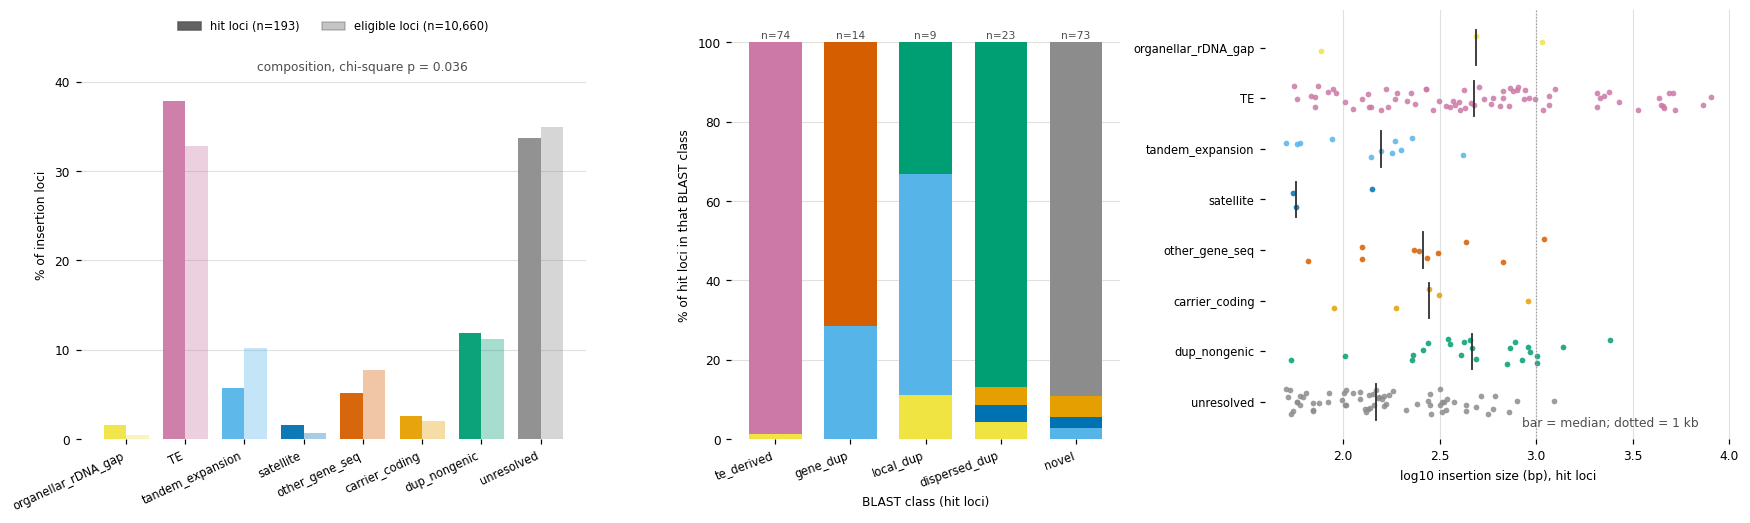

                        hits      %  eligible %  Fisher p
organellar_rDNA_gap        3   1.6%        0.4%     0.056
TE                        73  37.8%       32.9%     0.164
tandem_expansion          11   5.7%       10.2%     0.040
satellite                  3   1.6%        0.6%     0.136
other_gene_seq            10   5.2%        7.7%     0.220
carrier_coding             5   2.6%        2.0%     0.441
dup_nongenic              23  11.9%       11.2%     0.730
unresolved                65  33.7%       35.0%     0.761

BLAST class -> content class, hit loci (counts):
content_class  organellar_rDNA_gap  TE  tandem_expansion  satellite  other_gene_seq  carrier_coding  dup_nongenic  unresolved
cls                                                                                                                          
te_derived                       1  73                 0          0               0               0             0           0
gene_dup                         0   0            

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios":[1.3,1,1.2]})
x = np.arange(len(CONTENT)); w = 0.38
style(ax[0], axis="y")
ax[0].bar(x-w/2, [100*(L.content_class==c).mean() for c in CONTENT], w, color=[CCOL[c] for c in CONTENT], alpha=0.95, linewidth=0, label=f"hit loci (n={len(L)})")
ax[0].bar(x+w/2, [100*(E.content_class==c).mean() for c in CONTENT], w, color=[CCOL[c] for c in CONTENT], alpha=0.35, linewidth=0, label=f"eligible loci (n={len(E):,})")
ax[0].set_xticks(x); ax[0].set_xticklabels(CONTENT, fontsize=7.5, rotation=25, ha="right")
from matplotlib.patches import Patch
ax[0].set_ylabel("% of insertion loci"); ax[0].set_ylim(0, 48)
ax[0].legend(handles=[Patch(color="0.35", alpha=0.95, label=f"hit loci (n={len(L)})"),
                      Patch(color="0.35", alpha=0.35, label=f"eligible loci (n={len(E):,})")],
             frameon=False, fontsize=7.5, loc="upper center", ncol=2)
tab = np.array([[(L.content_class==c).sum() for c in CONTENT], [(E.content_class==c).sum() for c in CONTENT]])
chi = stats.chi2_contingency(tab)
note(ax[0], f"composition, chi-square p = {pfmt(chi[1])}", loc=(0.35,0.86))

style(ax[1], axis="y")
ct = pd.crosstab(L.cls, L.content_class).reindex(index=CARGO, columns=CONTENT).fillna(0)
sh = (ct.T / ct.sum(1)).T * 100
bot = np.zeros(len(CARGO))
for u in CONTENT:
    ax[1].bar(np.arange(len(CARGO)), sh[u].values, bottom=bot, width=0.7, color=CCOL[u], linewidth=0)
    bot += sh[u].values
for i, n in enumerate(ct.sum(1)): ax[1].text(i, 101, f"n={int(n)}", ha="center", fontsize=7, color="0.3")
ax[1].set_xticks(np.arange(len(CARGO))); ax[1].set_xticklabels(CARGO, fontsize=7.5, rotation=20, ha="right")
ax[1].set_ylabel("% of hit loci in that BLAST class"); ax[1].set_ylim(0, 108)
ax[1].set_xlabel("BLAST class (hit loci)")

style(ax[2], axis="x")
for i, u in enumerate(CONTENT):
    v = np.log10(L.loc[L.content_class==u, "size"])
    ax[2].scatter(v, np.full(len(v), i) + np.random.default_rng(i).uniform(-0.25, 0.25, len(v)),
                  s=14, color=CCOL[u], alpha=0.85, linewidth=0)
    if len(v): ax[2].plot([v.median()]*2, [i-0.35, i+0.35], color="0.2", lw=1.2)
ax[2].axvline(3, color=ZERO, lw=0.8, ls=":")
ax[2].set_yticks(range(len(CONTENT))); ax[2].set_yticklabels(CONTENT, fontsize=7.5); ax[2].invert_yaxis()
ax[2].set_xlabel("log10 insertion size (bp), hit loci")
note(ax[2], "bar = median; dotted = 1 kb", loc=(0.55,0.03))
fig.tight_layout(); plt.show()

print(f"{'':22}{'hits':>6}{'%':>7}{'eligible %':>12}{'Fisher p':>10}")
for c in CONTENT:
    a, b = int((L.content_class==c).sum()), int((E.content_class==c).sum())
    p = stats.fisher_exact([[a, len(L)-a], [b, len(E)-b]])[1]
    print(f"{c:<22}{a:>6}{100*a/len(L):>6.1f}%{100*b/len(E):>11.1f}%{pfmt(p):>10}")
print("\nBLAST class -> content class, hit loci (counts):"); print(ct.astype(int).to_string())
L["peri"] = L.cen_dist <= 2.5
print("\n% pericentromeric (within 2.5 Mb), hit loci:"); print((100*L.groupby("content_class").peri.mean()).reindex(CONTENT).round(0).to_string())

pd.set_option("display.width", 250)
cols = ["chrom","pos","size","tier","site_gene","cls","copied_gene","liftoff","pident","gea_nlp","freq_sum"]
for u in ["tandem_expansion","other_gene_seq","carrier_coding","organellar_rDNA_gap"]:
    t = L[L.content_class==u].sort_values("gea_nlp", ascending=False)
    print(f"\n{u}: {len(t)} hit loci"); print(t[cols + (["repeat"] if u.startswith("org") else [])].round(3).to_string(index=False))


## 2. The same comparison against a matched background

Hits differ from the eligible background in ways that also shift content class: they are more
frequent, more often pericentromeric (where TE insertions concentrate) and more often called in
only part of the panel. Here each hit is matched to background loci (hits removed) in the same
stratum of insertion frequency (quintile) x size (quintile) x pericentromeric (yes/no) x panel
support (called in < half of the 231 genomes, yes/no). Expected shares are the stratum-weighted
background shares; the band is the 2.5-97.5% range of 1,000 resampled matched sets. With 193 loci
over 8 classes, only shifts of several percentage points per class are detectable -- "no
difference" here means "no large difference".

In [3]:
K4 = ["chrom","pos","ref_len","alt_len"]
Eo = E[~E.set_index(K4).index.isin(L.set_index(K4).index)].copy()
for df in (L, Eo):
    df["n_called"] = pd.to_numeric(df.n_called, errors="coerce")
    df["peri"] = df.cen_dist <= 2.5
    df["low_support"] = df.n_called < 231 / 2
fq = np.quantile(Eo.freq_sum.dropna(), [0.2, 0.4, 0.6, 0.8]); sq = np.quantile(Eo["size"], [0.2, 0.4, 0.6, 0.8])
for df in (L, Eo):
    df["stratum"] = (pd.Series(np.searchsorted(fq, df.freq_sum.fillna(0)), index=df.index).astype(str) + "|"
                     + pd.Series(np.searchsorted(sq, df["size"]), index=df.index).astype(str)
                     + "|" + df.peri.astype(str) + "|" + df.low_support.astype(str))
pool = {k: g.content_class.to_numpy() for k, g in Eo.groupby("stratum")}
Lm = L[L.stratum.isin(pool)]
print(f"hits with a non-empty background stratum: {len(Lm)}/{len(L)}")
w = Lm.stratum.value_counts()
exp = sum(w[k] * pd.Series(pool[k]).value_counts(normalize=True).reindex(CONTENT).fillna(0) for k in w.index) / w.sum()
rng = np.random.default_rng(1)
sims = np.array([pd.Series(np.concatenate([rng.choice(pool[k], n) for k, n in w.items()])).value_counts(normalize=True)
                 .reindex(CONTENT).fillna(0).to_numpy() for _ in range(1000)])
obs = Lm.content_class.value_counts(normalize=True).reindex(CONTENT).fillna(0)
M = pd.DataFrame({"hits_%": 100*obs, "matched_expected_%": 100*exp,
                  "band_lo_%": 100*np.quantile(sims, 0.025, axis=0), "band_hi_%": 100*np.quantile(sims, 0.975, axis=0)}, index=CONTENT)
M["outside_band"] = (M["hits_%"] < M["band_lo_%"]) | (M["hits_%"] > M["band_hi_%"])
cnt = Lm.content_class.value_counts().reindex(CONTENT).fillna(0).to_numpy()
e_cnt = exp.to_numpy() * len(Lm)
keep = e_cnt >= 5
chi = stats.chisquare(np.append(cnt[keep], cnt[~keep].sum()), np.append(e_cnt[keep], e_cnt[~keep].sum()))
print(M.round(1).to_string())
print(f"\nmatched goodness-of-fit chi-square p = {pfmt(chi.pvalue)} (classes with expected < 5 pooled)")
print(f"unmatched (section 1) chi-square p = {pfmt(stats.chi2_contingency(np.array([[(L.content_class==c).sum() for c in CONTENT],[(E.content_class==c).sum() for c in CONTENT]]))[1])}")
print(f"\nhit loci with no trusted lift-back in any record (carrier-based classes untestable): "
      f"{int((L.carrier_evidence.astype(str)!='True').sum())}")


hits with a non-empty background stratum: 193/193


                     hits_%  matched_expected_%  band_lo_%  band_hi_%  outside_band
organellar_rDNA_gap     1.6                 1.0        0.0        2.6         False
TE                     37.8                35.4       29.5       41.5         False
tandem_expansion        5.7                 9.9        6.2       14.0          True
satellite               1.6                 0.6        0.0        2.1         False
other_gene_seq          5.2                 7.4        4.1       11.4         False
carrier_coding          2.6                 2.1        0.5        4.7         False
dup_nongenic           11.9                11.4        7.3       16.1         False
unresolved             33.7                32.2       26.4       37.8         False

matched goodness-of-fit chi-square p = 0.200 (classes with expected < 5 pooled)
unmatched (section 1) chi-square p = 0.036

hit loci with no trusted lift-back in any record (carrier-based classes untestable): 3


## 3. The same question asked of the raw descriptions

Before the combined class: the same comparison on the raw descriptions. Left: BLAST cargo class.
Middle: the any-overlap annotation flags (these are the flags the content class replaces with
bp-level coverage). Right: insertion size.

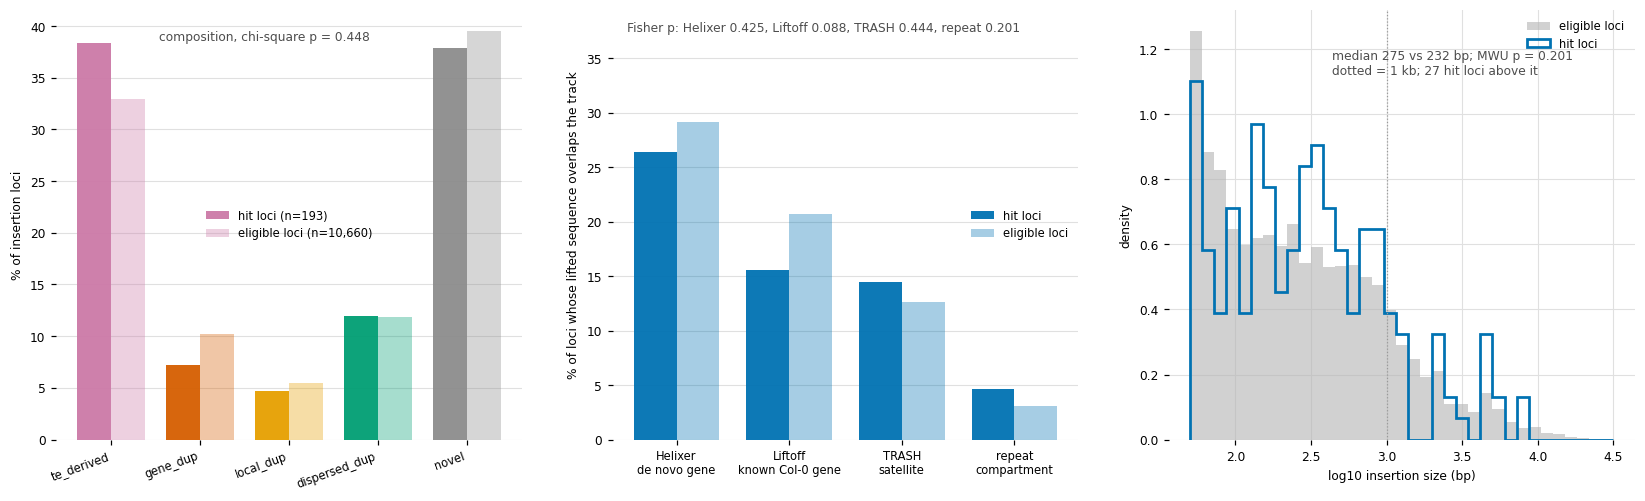

                      hits  eligible
te_derived           38.3%     32.9%
gene_dup              7.3%     10.2%
local_dup             4.7%      5.5%
dispersed_dup        11.9%     11.9%
novel                37.8%     39.5%
Helixer de novo gene   26.4%     29.2%
Liftoff known Col-0 gene   15.5%     20.7%
TRASH satellite      14.5%     12.6%
repeat compartment    4.7%      3.0%


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
w = 0.38; x = np.arange(len(CARGO))
style(ax[0], axis="y")
hv = [100*(L.cls==c).mean() for c in CARGO]; ev = [100*(E.cls==c).mean() for c in CARGO]
ax[0].bar(x-w/2, hv, w, color=[KCOL[c] for c in CARGO], alpha=0.95, label="hit loci (n=%d)"%len(L), linewidth=0)
ax[0].bar(x+w/2, ev, w, color=[KCOL[c] for c in CARGO], alpha=0.35, label="eligible loci (n=%s)"%f"{len(E):,}", linewidth=0)
ax[0].set_xticks(x); ax[0].set_xticklabels(CARGO, fontsize=7.5, rotation=20, ha="right")
ax[0].set_ylabel("% of insertion loci"); ax[0].legend(frameon=False, fontsize=7.5, loc="center")
tab = np.array([[(L.cls==c).sum() for c in CARGO], [(E.cls==c).sum() for c in CARGO]])
chi = stats.chi2_contingency(tab)
note(ax[0], f"composition, chi-square p = {pfmt(chi[1])}", loc=(0.22,0.93))

style(ax[1], axis="y")
feats = [("helixer_hit","Helixer\nde novo gene"),("liftoff_hit","Liftoff\nknown Col-0 gene"),
         ("trash_hit","TRASH\nsatellite"),("repeat_hit","repeat\ncompartment")]
xx = np.arange(len(feats))
ax[1].bar(xx-w/2, [100*L[c].mean() for c,_ in feats], w, color="#0072B2", alpha=0.95, label="hit loci", linewidth=0)
ax[1].bar(xx+w/2, [100*E[c].mean() for c,_ in feats], w, color="#0072B2", alpha=0.35, label="eligible loci", linewidth=0)
ax[1].set_xticks(xx); ax[1].set_xticklabels([l for _,l in feats], fontsize=7.5)
ax[1].set_ylabel("% of loci whose lifted sequence overlaps the track"); ax[1].legend(frameon=False, fontsize=7.5, loc="center right")
ps = []
for c,_ in feats:
    a, b = int(L[c].sum()), int(E[c].sum())
    ps.append(stats.fisher_exact([[a, len(L)-a],[b, len(E)-b]])[1])
ax[1].set_ylim(0, max(max(100*L[c].mean(), 100*E[c].mean()) for c,_ in feats) * 1.35)
note(ax[1], "Fisher p: " + ", ".join(f"{l.split(chr(10))[0]} {pfmt(p)}" for (_,l),p in zip(feats, ps)), loc=(0.03,0.95))

style(ax[2])
bins = np.linspace(1.7, 4.5, 36)
ax[2].hist(np.log10(E["size"]), bins=bins, density=True, color="0.7", alpha=0.6, label="eligible loci", linewidth=0)
ax[2].hist(np.log10(L["size"]), bins=bins, density=True, histtype="step", color="#0072B2", lw=1.8, label="hit loci")
ax[2].axvline(3, color=ZERO, lw=0.8, ls=":")
ax[2].set_xlabel("log10 insertion size (bp)"); ax[2].set_ylabel("density"); ax[2].legend(frameon=False, fontsize=7.5)
mw = stats.mannwhitneyu(L["size"], E["size"]).pvalue
note(ax[2], f"median {L['size'].median():,.0f} vs {E['size'].median():,.0f} bp; MWU p = {pfmt(mw)}\n"
            f"dotted = 1 kb; {int((L['size']>=1000).sum())} hit loci above it", loc=(0.35,0.85))
fig.tight_layout(); plt.show()

print(f"{'':18}{'hits':>8}{'eligible':>10}")
for c in CARGO: print(f"{c:<18}{100*(L.cls==c).mean():>7.1f}%{100*(E.cls==c).mean():>9.1f}%")
for c,l in feats: print(f"{l.replace(chr(10),' '):<18}{100*L[c].mean():>7.1f}%{100*E[c].mean():>9.1f}%")


## 4. What the insertion carries, by where it landed

Each bar is one placement tier from the gene screen (`build_functional_variants.py`), ordered from
inside a gene (left) to nowhere near one (right); the dotted line separates the tiers with a gene handle
from those without. Bar colour is the cargo of the inserted sequence. The no-gene-handle tiers are the
ones the gene screen could not evaluate -- this is the first look at what they contain.

Two things to keep in mind when reading `gene_dup` and `novel` in the genic tiers: an insertion inside
gene X often BLASTs back to gene X itself (it carries a fragment of the gene it sits in), and `novel`
means "too short to align" far more often than "new sequence" -- and most insertions here are short.

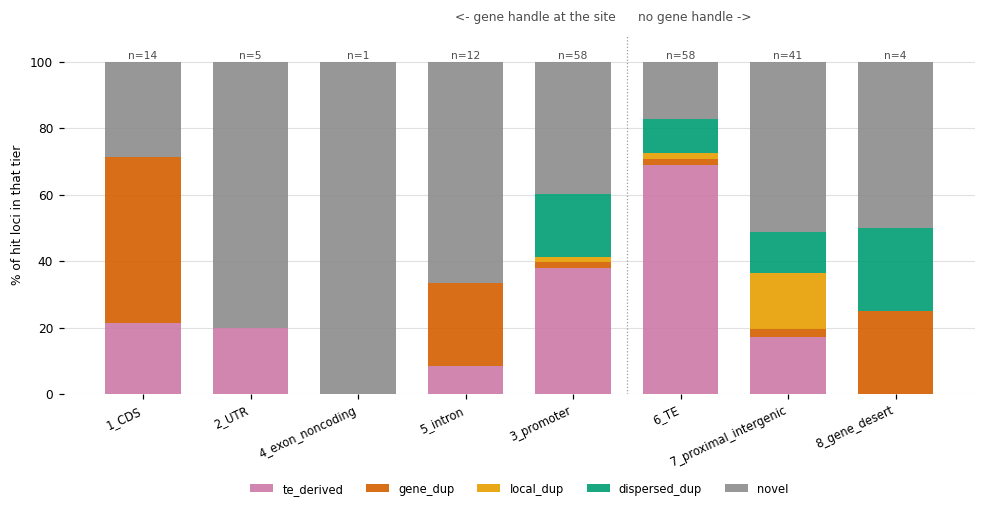

site tier x cargo (counts):
cls                    dispersed_dup  gene_dup  local_dup  novel  te_derived
tier                                                                        
1_CDS                              0         7          0      4           3
2_UTR                              0         0          0      4           1
4_exon_noncoding                   0         0          0      1           0
5_intron                           0         3          0      8           1
3_promoter                        11         1          1     23          22
6_TE                               6         1          1     10          40
7_proximal_intergenic              5         1          7     21           7
8_gene_desert                      1         1          0      2           0

Liftoff gene overlaps: 30 loci; 26 are only the insertion's own site gene (site context restated, not cargo). The 4 that include a different gene:
chrom      pos  size           cls     family      gen

In [5]:
TIERS = ["1_CDS","2_UTR","4_exon_noncoding","5_intron","3_promoter","6_TE","7_proximal_intergenic","8_gene_desert"]
fig, ax = plt.subplots(figsize=(9, 4.8))
style(ax, axis="y")
ct = pd.crosstab(L.tier, L.cls).reindex(TIERS).fillna(0)
n_t = ct.sum(1); sh = (ct.T / n_t).T * 100
bot = np.zeros(len(TIERS))
for c in CARGO:
    ax.bar(np.arange(len(TIERS)), sh[c].values, bottom=bot, width=0.7, color=KCOL[c], alpha=0.9, label=c, linewidth=0)
    bot += sh[c].values
for i, (t, n) in enumerate(n_t.items()):
    ax.text(i, 101, f"n={int(n)}", ha="center", fontsize=7, color="0.3")
ax.axvline(4.5, color=ZERO, lw=0.8, ls=":")
ax.set_xticks(np.arange(len(TIERS))); ax.set_xticklabels(TIERS, fontsize=7.5, rotation=25, ha="right")
ax.set_ylabel("% of hit loci in that tier"); ax.set_ylim(0, 108)
ax.legend(frameon=False, fontsize=7.5, ncol=5, loc="upper center", bbox_to_anchor=(0.5,-0.22))
ax.annotate("<- gene handle at the site", xy=(4.4, 1.04), xycoords=("data", "axes fraction"), ha="right", fontsize=8, color="0.3", annotation_clip=False)
ax.annotate("no gene handle ->", xy=(4.6, 1.04), xycoords=("data", "axes fraction"), ha="left", fontsize=8, color="0.3", annotation_clip=False)
fig.tight_layout(); plt.show()

print("site tier x cargo (counts):"); print(ct.astype(int).to_string())

lo = L[L.liftoff_hit].copy()
lo["lift_genes"] = lo.liftoff.str.split(",").apply(lambda v: [x.split("_")[0] for x in v])
lo["other"] = [",".join(sorted(set(g) - {s})) for s, g in zip(lo.gene.astype(str), lo.lift_genes)]
print(f"\nLiftoff gene overlaps: {len(lo)} loci; {int((lo.other=='').sum())} are only the insertion's own site gene "
      f"(site context restated, not cargo). The {int((lo.other!='').sum())} that include a different gene:")
print(lo.loc[lo.other!="", ["chrom","pos","size","cls","family","gene","other","freq_sum"]].to_string(index=False))

pd.set_option("display.width", 250)
cols = ["chrom","pos","size","n_rec","freq_sum","tier","nearest_gene","dist_to_gene","cls","family","pident",
        "helixer_hit","liftoff","gea_best_axis","gea_nlp","gwas_n_gardens"]
big = L[L["size"]>=1000].sort_values("size", ascending=False)
print(f"\nall {len(big)} hit loci >= 1 kb -- the only ones large enough to carry a gene-sized element "
      f"({int((big.cls=='te_derived').sum())} TE-derived):")
print(big[cols].round(3).to_string(index=False))


## 5. Where the hit insertions sit in the genome, and the loci whose records disagree

One row per chromosome; every point is a hit insertion locus, coloured by cargo class. The grey band is
+/- 2.5 Mb around the approximate TAIR10 centromere midpoint. Points above the chromosome line have a
gene handle at the site; points below do not.

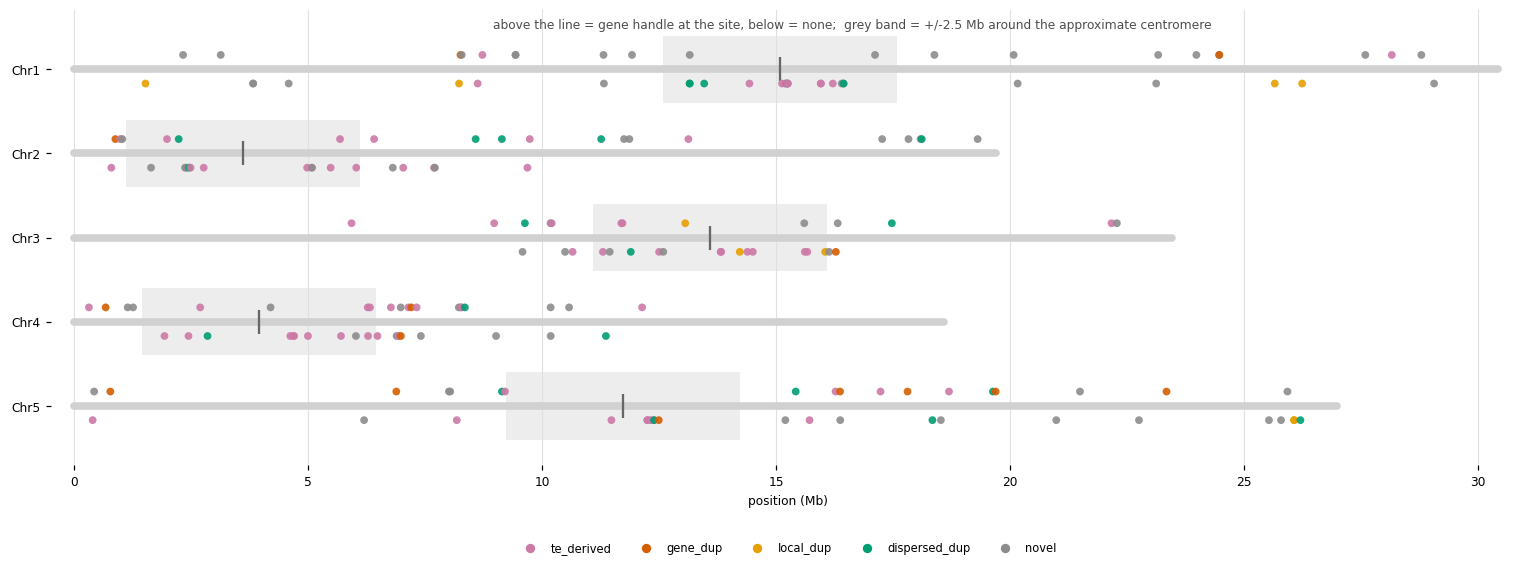

hit loci within 2.5 Mb of a centromere, by cargo class:
               arm  pericentromeric  % pericentromeric
cls                                                   
te_derived      31               43               58.0
gene_dup        13                1                7.0
local_dup        6                3               33.0
dispersed_dup   13               10               43.0
novel           60               13               18.0

overall: hits with gene handle 14% pericentromeric, without 55%, eligible background 27%

TE families among pericentromeric te_derived hits:
family
ATREP18      5
ATLANTYS2    2
ATHILA       2
ATLANTYS1    2
ATCOPIA95    2
ATHILA4C     1
HARBINGER    1
ATMU11       1
ATGP8        1
ATGP1        1

5 hit loci whose split records disagree on the BLAST class (one row per locus is used everywhere above; the per-record table is results/sv_hit_cargo_records.csv):
chrom      pos  size  n_rec                       cls_all              family_all    content_cla

In [6]:
fig, ax = plt.subplots(figsize=(14, 5.2))
style(ax, axis="x")
chroms = list(CEN)
for i, ch in enumerate(chroms):
    y = len(chroms) - 1 - i
    ax.add_patch(plt.Rectangle((CEN[ch]-2.5, y-0.4), 5, 0.8, color="0.93", zorder=0, linewidth=0))
    ax.plot([0, CHRLEN[ch]], [y, y], color="0.82", lw=5, solid_capstyle="round", zorder=1)
    ax.plot([CEN[ch]], [y], marker="|", color="0.4", ms=16, mew=1.5, zorder=2)
    s = L[L.chrom==ch]
    for h, dy in ((True, 0.17), (False, -0.17)):
        t = s[s.gene_handle==h]
        ax.scatter(t.pos/1e6, np.full(len(t), y+dy), s=26, color=[KCOL[c] for c in t.cls],
                   alpha=0.9, linewidth=0, zorder=3)
ax.set_yticks(range(len(chroms))); ax.set_yticklabels(chroms[::-1])
ax.set_xlabel("position (Mb)"); ax.set_xlim(-0.5, 31); ax.set_ylim(-0.7, len(chroms)-0.3)
for c in CARGO: ax.scatter([], [], color=KCOL[c], s=26, label=c)
ax.legend(frameon=False, fontsize=7.5, loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=5)
note(ax, "above the line = gene handle at the site, below = none;  grey band = +/-2.5 Mb around the approximate centromere", loc=(0.30,0.96))
fig.tight_layout(); plt.show()

L["peri"] = L.cen_dist <= 2.5
print("hit loci within 2.5 Mb of a centromere, by cargo class:")
t = pd.crosstab(L.cls, L.peri).reindex(CARGO).fillna(0).astype(int)
t.columns = ["arm", "pericentromeric"]; t["% pericentromeric"] = (100*t.pericentromeric/(t.sum(1))).round(0)
print(t.to_string())
print(f"\noverall: hits with gene handle {100*L.loc[L.gene_handle,'peri'].mean():.0f}% pericentromeric, "
      f"without {100*L.loc[~L.gene_handle,'peri'].mean():.0f}%, eligible background {100*(E.cen_dist<=2.5).mean():.0f}%")
print("\nTE families among pericentromeric te_derived hits:")
print(L.loc[L.peri & (L.cls=="te_derived"), "family"].replace("","?").value_counts().head(10).to_string())

S = L.copy(); S["n_cls"] = S.n_cls.astype(int)
mixed = S[S.n_cls > 1]
print(f"\n{len(mixed)} hit loci whose split records disagree on the BLAST class "
      f"(one row per locus is used everywhere above; the per-record table is results/sv_hit_cargo_records.csv):")
print(mixed[["chrom","pos","size","n_rec","cls_all","family_all","content_class","tier","gea_nlp"]].round(2).to_string(index=False))
print(f"\nloci with no trusted lift-back in any record (carrier-based classes untestable): "
      f"{int((L.carrier_evidence.astype(str)!='True').sum())}")


## 6. What each hit is, and where it landed

Content class (what the inserted sequence is), split by where it landed. The landing site is the
most severe effect over **all transcripts** of the gene(s) at the site.

### What the six annotation layers deliver, and what they do not

Two layers carry most of the information, two carry some, and two come back essentially empty. The
empty ones are a result rather than a failure, so they are stated here once instead of at every card.

| layer | delivers |
|---|---|
| **RepeatMasker** (`rm_*`) | a repeat family for 100/193 loci -- but 17 of those are `Simple_repeat` / `Low_complexity`, which RepeatMasker emits whatever library it is given and which are *not* TE calls. **83 loci get a genuine TE family**, and with it the two things a BLAST class cannot give: divergence from the TAIR10 copy, and how much of that element is present. |
| **mmseqs recurrence** (`rec_*`) | 71/193 loci carry sequence that recurs at another panel insertion locus -- the only handle that works on sequence absent from Col-0, and the layer that most strongly tracks the TE calls (66% of TE-family loci recur, against 15% of the rest). |
| **TRF** (`trf_*`) | a tandem array in 39/193. |
| **blastx** (`prot_*`) | a protein hit in 42/193, of which 10 are TE-encoded (gag/pol/transposase). |
| **carrier landing site** (`car_*`) | the carrier's own gene models at the site for the 951 lifted records; see the caveat in section 14 -- coverage is still measured over the whole lifted allele. |
| **structural signatures** (`str_*`) | **almost nothing, and that is the finding.** Not one of the 1,008 records carries a terminal direct repeat (LTR pair) or a terminal inverted repeat of any length. This is consistent with what RepeatMasker shows in section 10: the median TE call covers ~12% of its element, so there are no full-length elements here that could carry ends. |

**Target-site duplications are at chance below 4 bp.** The raw search reports a flanking direct repeat
at 103/951 records (10.8%), but permuting the flanks *between* records reproduces that rate exactly
(null 10.3%, 95% range 8.3-11.8%, p = 0.32) -- most calls are 2 bp, which a random pair of flanks
matches about one time in sixteen. Only **TSD >= 4 bp** sits above the null (2.4% observed vs 1.1%,
p = 0.005), so that is the threshold used everywhere below. It leaves **4 loci**, not 22.

Layer output is attached as annotation: `repeat_family`, `rm_div`, `rec_n_loci`, `trf_*` and a one-line
`LAYERS:` summary on each card. **No locus changes content class because of it** -- a 1-10% fragment of
a Helitron at 20% divergence says the sequence is repeat-derived, not that the insertion is a
transposition event. The 12 loci where that distinction bites are listed in sections 11 and 12.

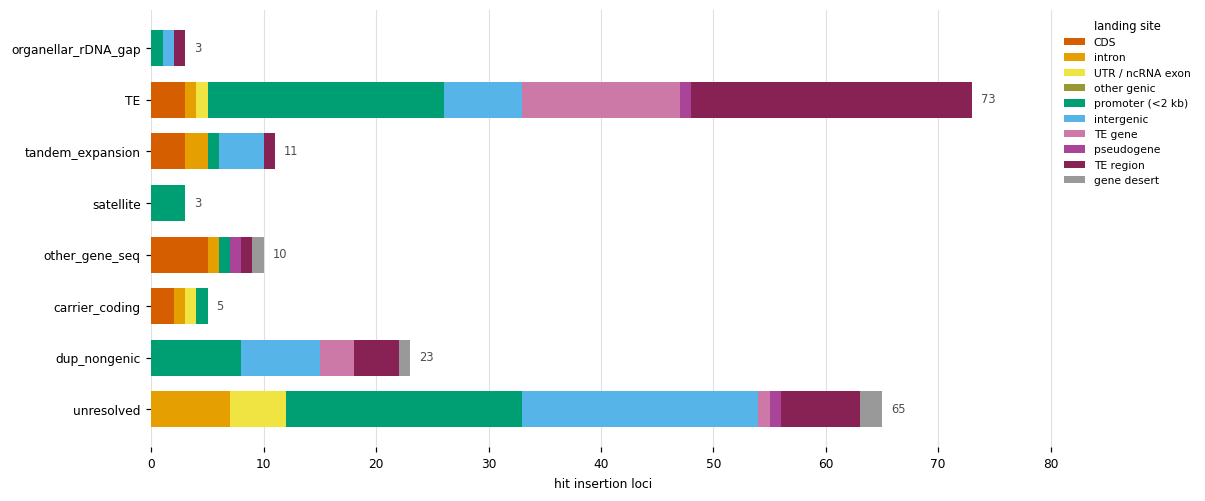

site_cat             CDS  intron  UTR / ncRNA exon  other genic  promoter (<2 kb)  intergenic  TE gene  pseudogene  TE region  gene desert
content_class                                                                                                                             
unresolved             0       7                 5            0                21          21        1           1          7            2
dup_nongenic           0       0                 0            0                 8           7        3           0          4            1
carrier_coding         2       1                 1            0                 1           0        0           0          0            0
other_gene_seq         5       1                 0            0                 1           0        0           1          1            1
satellite              0       0                 0            0                 3           0        0           0          0            0
tandem_expansion       3   

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.6))
style(ax, axis="x")
ct = pd.crosstab(D.content_class, D.site_cat).reindex(index=CONTENT[::-1], columns=SITES).fillna(0)
left = np.zeros(len(ct))
for s in SITES:
    ax.barh(np.arange(len(ct)), ct[s], left=left, color=SCOL[s], height=0.7, linewidth=0, label=s)
    left += ct[s].values
for i, n in enumerate(left): ax.text(n + 0.8, i, f"{int(n)}", va="center", fontsize=7.5, color="0.3")
ax.set_xlim(0, left.max() * 1.1)
ax.set_yticks(np.arange(len(ct))); ax.set_yticklabels(ct.index)
ax.set_xlabel("hit insertion loci")
ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0), title="landing site", title_fontsize=7.5)
fig.tight_layout(); plt.show()
print(ct.astype(int).to_string())

print("\n--- annotation layers, by content class (annotation only: class is unchanged) ---")
lay = D.groupby("content_class").agg(
    n=("chrom","size"), te_family=("rm_is_te","sum"),
    simple_only=("repeat_family", lambda s: int((s=="(simple/low-cplx)").sum())),
    recurs=("recurs","sum"), tandem_TRF=("trf_period", lambda s: int((s>0).sum())),
    prot_TE=("prot_is_te","sum"), tsd4=("real_tsd","sum"),
    med_div=("rm_div_te","median")).reindex(CONTENT).dropna(how="all")
icol = [c for c in lay.columns if c != "med_div"]                  # med_div stays NaN where no TE call
lay[icol] = lay[icol].fillna(0).astype(int)
print(lay.round(1).to_string(na_rep="-"))
print(f"\nterminal direct repeats: {int((D.str_ltr_len>0).sum())}/193    terminal inverted repeats: "
      f"{int((D.str_tir_len>=10).sum())}/193    TSD >= {MIN_REAL_TSD} bp: {int(D.real_tsd.sum())}/193 "
      f"(any length, incl. chance: {int((D.str_tsd_len>0).sum())})")
print(f"no signal from any layer: {int((D.annotation=='no signal from any layer').sum())}/193")


## 7. The insertions that change a coding sequence

For every transcript of every gene the changed REF span touches, the whole mutant CDS is translated
and compared with the reference protein (changes wholly inside one CDS exon), or the coding bases
removed are counted (changes that cross an exon boundary or delete a whole CDS). The locus shows its
most severe transcript; `isoform_effects` lists all. Labels: `truncating` = the protein ends earlier
than the reference; `frameshift` = frame changes but the protein is not shorter; `in-frame` = residues
added/removed, no new stop; `altered` = a new stop inside the inserted bases leaves the protein the
reference length. **Read each card with its support line**: several of these rest on a panel call
made in only a third of the genomes, or on a rare GWAS-only allele. The translation was checked on the UBQ3 insertion, which comes out as
exactly one ubiquitin monomer (MQIFVKTLTGK...LRLRGG). `stop_records` = records of the locus whose
own ALT gives a premature stop.

In [8]:
c = D[D.site_feature.astype(str).str.startswith("CDS")]
print(c.site_feature.value_counts().to_string()); print()
cards(c, extra=("truncating_records","wt_context","mut_context","ins_peptide","isoform_effects"))


site_feature
CDS:truncating           5
CDS:in-frame             4
CDS:frameshift           2
CDS:altered              1
CDS:whole-CDS-deleted    1

Chr4:7,204,359   GEA -log10p 8.9 (bio11)   insertion freq 0.50   14 records   39 carrier genomes, called in 78/231
   IS    : 312 bp fragment of AT1G13960 [Probable WRKY transcription factor 4 (WRKY DNA-binding protein 4)] (90% id)
   DOES  : CDS of AT4G12020 [Probable WRKY transcription factor 19 (WRKY DNA-binding protein 19)] (AT4G12020.1) at codon 662/1798: in-frame +104 aa, no new stop (1798 -> 1902 aa) [all 3 transcripts agree]
   LAYERS: protein: tr|Q0WPM8|Q0WPM8_ARATH Putative WRKY DNA-binding protein (76% over 45 aa)
   truncating_records: 0/14
   wt_context: KVVKGNPYPRFSSSKDYDVVI
   mut_context: KVVKGNPYPRSYYKCTTLGCGARKHVEREATDPKDVVTTYESEHNHGFPAAKSSSIDSVIAQNSVNYDIFPLISSKNYQDAELSIGFPWSQGLSVDEAFTDTRDFFGSLSTRVRFSSSKDYDVVI
   ins_peptide: SYYKCTTLGCGARKHVEREATDPKDVVTTYESEHNHGFPAAKSSSIDSVIAQNSVNYDIFPLISSKNYQDAELSIGFPWSQGLSVDEAFTDTRDFFG

## 8. Tandem expansions -- an extra copy of the sequence right beside it

The insertion is >= 50% covered by sequence within 50 bp of the site. These are the loci where
"what is it" has a crisp answer: one more unit of whatever is already there. When the unit is
inside a gene, the consequence line says what that does.

In [9]:
cards(D[D.content_class=="tandem_expansion"], extra=("ins_seq",))
te_adj = D[(D.content_class=="TE") & (D.max_flank_adj>=0.5)]
print(f"(plus {len(te_adj)} TE loci that are also copies of the adjacent TE -- listed under TE)")


Chr5:26,073,562   GEA -log10p 9.1 (bio1)   insertion freq 0.55   21 records   103 carrier genomes, called in 189/231
   IS    : 199 bp tandem expansion of the adjacent non-genic sequence: extra copy of the sequence next to it (100% covered, 94% id); TRASH 199_69 array, 100% of the insertion
   DOES  : intergenic; nearest gene AT5G65240 [Probable LRR receptor-like serine/threonine-protein kinase At5g65240 (EC 2.7.11.1)] at 840 bp
   LAYERS: Low_complexity A-rich (full-length, 20.5% diverged); poly-A/T tail 8 bp; recurs at 11 panel insertion loci on 3 chromosomes
   ins_seq: AAAAAAAATCAAAACTCTTACTATGTTATATGATTTTTTTTAAAAACGCTAAATATACAAAATAAATGCTAAATATACATGAAGATGTGAAAAACATGTTGGATTATTGGAATCGCTAATGATCACGGTTAAATGGCGGGATCCAAAATCCGGTTAGATTTCACAACGTCATATTAATTTAGTATTATTATATAATTTT
   NOTE  : lifted 90% of records

Chr1:8,224,955   GEA -log10p 7.7 (pc3)   insertion freq 0.11   1 records   23 carrier genomes, called in 213/231
   IS    : 51 bp tandem expansion of the adjacent non-genic sequence: ext

## 9. Sequence of another Col-0 gene, and coding sequence in a carrier gene model

`other_gene_seq`: the best TAIR10 match is a gene other than the one at the site (all are
fragments, 66-1,092 bp). `carrier_coding`: no Col-0 match, but most of the insertion is CDS in the
carrier's gene model -- either a carrier-specific exon or a model that differs from Col-0's. An
**orphan** Helixer model has no Liftoff (Col-0) gene overlapping it.

In [10]:
print("=== other_gene_seq ===\n"); cards(D[D.content_class=="other_gene_seq"], extra=("col0_top_hits",))
print("=== carrier_coding ===\n");  cards(D[D.content_class=="carrier_coding"], extra=("c_helixer_orphan","c_liftoff_genes"))


=== other_gene_seq ===

Chr4:6,982,683   GEA -log10p 10.9 (bio6)   insertion freq 0.18   2 records   14 carrier genomes, called in 78/231
   IS    : 1,092 bp fragment of AT4G11530 [Cysteine-rich receptor-like protein kinase 34 (Cysteine-rich RLK34) (EC 2.7.11.1)] (76% id)
   DOES  : exon(non-coding) of AT4G11500 [miscRNA] (pseudogene) (AT4G11500.1)
   LAYERS: protein: tr|A0A1P8B8H5|A0A1P8B8H5_ARATH Serine/threonine-protein (37% over 303 aa)
   col0_top_hits: Chr4:6988k AT4G11530(protein_coding_gene) 76%/100% ; Chr4:6983k AT4G11500(pseudogene) 85%/48% ; Chr4:6986k AT4G11521(protein_coding_gene) 73%/18%
   NOTE  : orphan Helixer model; replacement allele: ALT replaces 909 bp of Col-0; genotyped in only 78 of 231 panel genomes

Chr5:23,346,212   GEA -log10p 10.7 (pc1)   insertion freq 0.23   4 records   52 carrier genomes, called in 227/231
   IS    : 247 bp fragment of AT1G18660 [Zinc finger (C3HC4-type RING finger) family protein] (86% id)
   DOES  : intron 1/1, 50 bp from the nearest e

Chr5:8,036,567   GEA -log10p 6.6 (bio6)   insertion freq 0.13   1 records   10 carrier genomes, called in 78/231
   IS    : 278 bp no Col-0 match; 100% of it is CDS of a carrier gene model
   DOES  : CDS of AT5G23840 [MD-2-related lipid recognition domain-containing protein] (AT5G23840.2) at codon 128/140: frameshift; C-terminus replaced, 140 -> 143 aa [most severe of 2 transcripts; they differ]
   c_liftoff_genes: AT5G23840
   NOTE  : genotyped in only 78 of 231 panel genomes

Chr2:9,140,325   GEA -log10p 6.3 (bio3)   insertion freq 0.38   7 records   30 carrier genomes, called in 78/231
   IS    : 905 bp BLAST dispersed_dup (99% id); 62% of it is CDS of an ORPHAN Helixer model (no Col-0 gene)
   DOES  : promoter/upstream; nearest gene AT2G21370 [D-ribulose kinase (D-ribulokinase) (EC 2.7.1.47) (Inactive Xylulose kinase 1) (Atxk-1)] at 244 bp
   LAYERS: Simple_repeat (T)n (full-length, 0.0% diverged); TE protein: tr|A0MFH0|A0MFH0_ARATH RNase H type-1 domain-containing protein (Fragmen

## 10. Transposable elements

Superfamily comes from TAIR's own per-element table (`TAIR10_Transposable_Elements.txt`; every
family maps to one superfamily there). Left: superfamily by landing site. Right: size by superfamily.

### These are old fragments, not transposition events

The BLAST class answers "does this sequence look like a TE?" and stops there. RepeatMasker answers two
further questions, and both answers point the same way. **66 of the 73 TE loci get a RepeatMasker
family** (5 get none, 2 only a simple repeat), and it agrees with the BLAST family call at 42/66.

| | |
|---|---|
| divergence from the TAIR10 copy | median **10.1%** (IQR 6.2-18.7, range 0-33.5); **2** loci below 2%, 33 above 10%, 15 above 20% |
| fraction of that element present | median **0.12** (IQR 0.02-0.35); **31** cover less than a tenth of it, only **3** are near-full-length |
| terminal repeats (LTR pair / TIR) | **0 of 66** |
| TSD >= 4 bp | **3 of 66** |
| TE-encoded protein (gag/pol/transposase) | **6 of 66** |

A recent transposition leaves a near-identical, near-complete copy with intact ends and a target-site
duplication. Almost none of that is here: the typical hit carries a **tenth of an element that last
shared an ancestor with its Col-0 relative long enough ago to drift 10%**, with no ends and no TSD.
What the hits carry is TE-*derived sequence*, and calling a locus "a TE insertion" overstates it.

Two caveats on the divergence number. It is measured against **the longest TAIR10 copy of each family,
not a true consensus**, so it is a proxy for age rather than a calibrated one -- a family whose longest
Col-0 copy is itself degraded will read as more diverged than it is. And a short fragment gives the
aligner little to work with, so the estimate is noisiest exactly where coverage is lowest.

What *does* corroborate the TE calls is recurrence, not structure: **46 of 66 recur at another panel
insertion locus** (median 34 loci, up to 844), against 15% of non-TE hits, and 25 of 66 carry a tandem
array. Recurrence across independent insertion sites is what mobile sequence looks like even when every
individual copy is a degraded fragment.

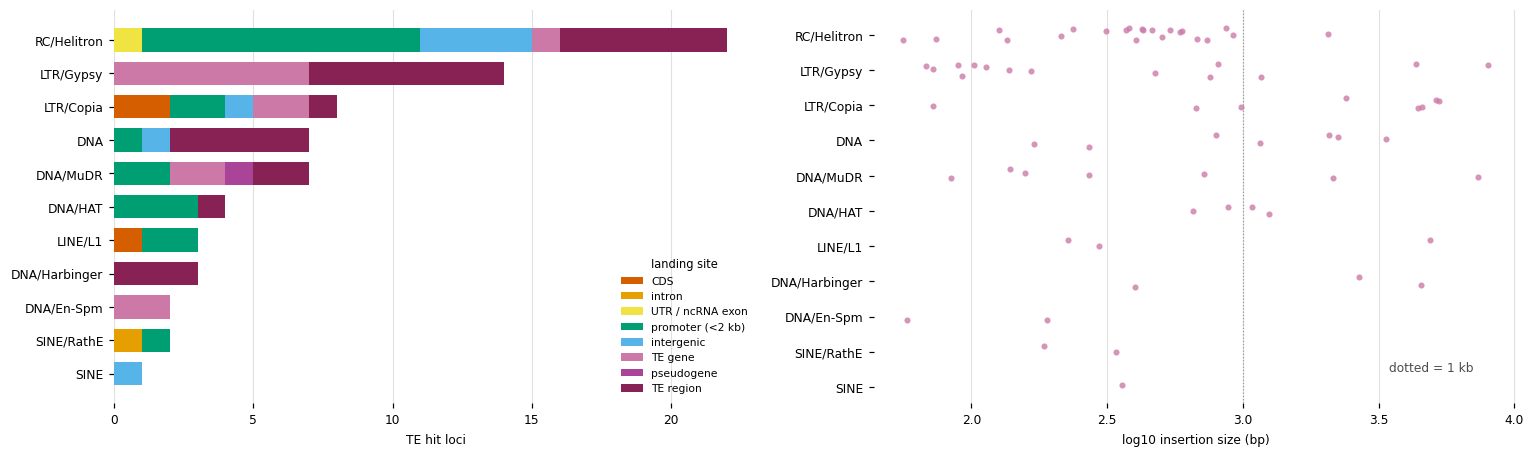

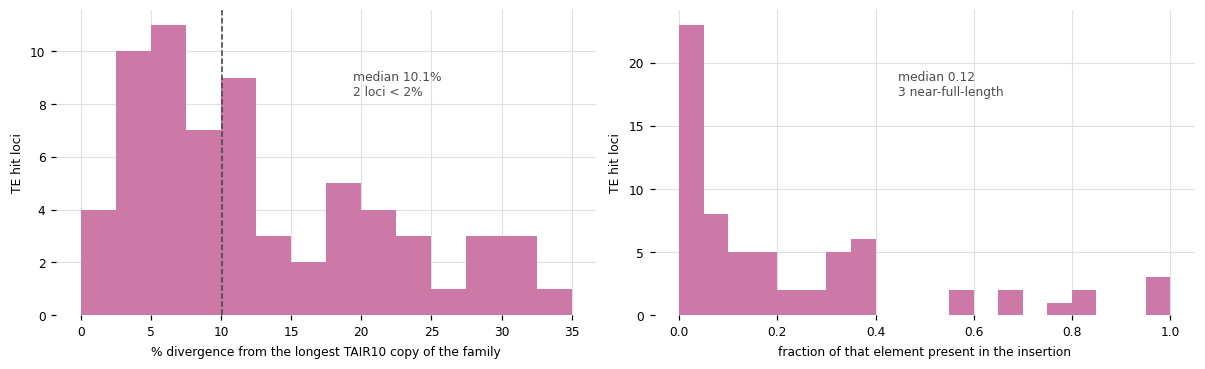

RepeatMasker and the BLAST class name the same family at 42/66 TE loci with both calls
TE loci with a RepeatMasker family: 66/73;  recur at another panel locus: 46/66;  tandem array: 25/66;  TE protein: 6/66;  terminal repeats: 0;  TSD >= 4 bp: 3
pericentromeric (<= 2.5 Mb): 42/73;  >= 1 kb: 20;  inside a TAIR10 TE gene: 14;  within 2 kb upstream of a gene: 21

TE loci in or next to protein-coding genes (CDS / intron / UTR / promoter):

Chr4:8,279,304   GEA -log10p 10.4 (bio15)   insertion freq 0.20   12 records   40 carrier genomes, called in 198/231
   IS    : 596 bp ATREP2A (RC/Helitron) TE sequence, 97% id to Col-0; 64 Col-0 loci match >=50% of its length at >=80% id in one HSP
   DOES  : promoter/upstream; nearest gene AT4G14370 [ADP-ribosyl cyclase/cyclic ADP-ribose hydrolase (EC 3.2.2.6)] at 337 bp
   LAYERS: RC/Helitron ATREP2A (34% of the consensus, 10.8% diverged); recurs at 238 panel insertion loci on 5 chromosomes

Chr2:6,409,342   GEA -log10p 8.3 (pc3)   insertion freq 0.0

In [11]:
T = D[D.content_class=="TE"].copy()
T["te_superfamily"] = T.te_superfamily.replace({"": "?"})
SF = T.te_superfamily.value_counts().index.tolist()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
style(ax[0], axis="x")
ct = pd.crosstab(T.te_superfamily, T.site_cat).reindex(index=SF[::-1], columns=[s for s in SITES if s in set(T.site_cat)]).fillna(0)
left = np.zeros(len(ct))
for s in ct.columns:
    ax[0].barh(np.arange(len(ct)), ct[s], left=left, color=SCOL[s], height=0.7, linewidth=0, label=s); left += ct[s].values
ax[0].set_yticks(np.arange(len(ct))); ax[0].set_yticklabels(ct.index); ax[0].set_xlabel("TE hit loci")
ax[0].legend(frameon=False, fontsize=7, loc="lower right", title="landing site", title_fontsize=7.5)
style(ax[1], axis="x")
for i, sf in enumerate(SF[::-1]):
    v = np.log10(T.loc[T.te_superfamily==sf, "size"])
    ax[1].scatter(v, np.full(len(v), i) + np.random.default_rng(i).uniform(-0.2,0.2,len(v)), s=16, color="#CC79A7", alpha=0.8, linewidth=0)
ax[1].set_yticks(range(len(SF))); ax[1].set_yticklabels(SF[::-1]); ax[1].set_xlabel("log10 insertion size (bp)")
ax[1].axvline(3, color="0.6", lw=0.8, ls=":")
note(ax[1], "dotted = 1 kb", loc=(0.80,0.08))
fig.tight_layout(); plt.show()

# age and completeness of the TE calls -- the two things the BLAST class cannot give
t = T[T.rm_is_te]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a in ax: style(a)
ax[0].hist(t.rm_div, bins=np.arange(0, 36, 2.5), color="#CC79A7", linewidth=0)
ax[0].axvline(t.rm_div.median(), color="0.25", lw=1, ls="--")
ax[0].set_xlabel("% divergence from the longest TAIR10 copy of the family"); ax[0].set_ylabel("TE hit loci")
note(ax[0], f"median {t.rm_div.median():.1f}%\n{int((t.rm_div<2).sum())} loci < 2%", loc=(0.55, 0.72))
ax[1].hist(t.rm_cons_frac, bins=np.arange(0, 1.05, 0.05), color="#CC79A7", linewidth=0)
ax[1].set_xlabel("fraction of that element present in the insertion"); ax[1].set_ylabel("TE hit loci")
note(ax[1], f"median {t.rm_cons_frac.median():.2f}\n{int((t.rm_cons_frac>=0.9).sum())} near-full-length", loc=(0.45, 0.72))
fig.tight_layout(); plt.show()
both = t[t.family.astype(str).ne("")]
agree = sum(rf.split("_AT")[0].upper() in bf.upper() or bf.upper() in rf.upper()
            for rf, bf in zip(both.rm_family, both.family))
print(f"RepeatMasker and the BLAST class name the same family at {agree}/{len(both)} TE loci with both calls")
print(f"TE loci with a RepeatMasker family: {int(T.rm_is_te.sum())}/{len(T)};  "
      f"recur at another panel locus: {int((t.rec_n_loci>1).sum())}/{len(t)};  tandem array: {int((t.trf_period>0).sum())}/{len(t)};  "
      f"TE protein: {int(t.prot_is_te.sum())}/{len(t)};  terminal repeats: {int((t.str_ltr_len>0).sum())};  "
      f"TSD >= {MIN_REAL_TSD} bp: {int(t.real_tsd.sum())}")
print(f"pericentromeric (<= 2.5 Mb): {int((T.cen_dist<=2.5).sum())}/{len(T)};  >= 1 kb: {int((T['size']>=1000).sum())};  "
      f"inside a TAIR10 TE gene: {int((T.site_cat=='TE gene').sum())};  within 2 kb upstream of a gene: {int((T.site_cat=='promoter (<2 kb)').sum())}")
print("\nTE loci in or next to protein-coding genes (CDS / intron / UTR / promoter):\n")
cards(T[T.site_cat.isin(["CDS","intron","UTR / ncRNA exon","promoter (<2 kb)"])])
print("\nall other TE loci (TE regions, TE genes, intergenic, pericentromere):\n")
rest = T[~T.site_cat.isin(["CDS","intron","UTR / ncRNA exon","promoter (<2 kb)"])]
print(rest.sort_values("gea_nlp", ascending=False)[["chrom","pos","size","family","te_superfamily","pident","repeat_family","rm_div","rm_cons_frac","rec_n_loci","site_cat","nearest_gene","dist_to_gene","gea_nlp","freq_sum","caveats"]].round(2).to_string(index=False))


## 11. Duplications, satellites, organellar / rDNA

**Seven of the 23 non-genic duplications carry a RepeatMasker TE family** that the BLAST class did not
name: four Helitrons (ATREP7, ATREP10C, ATREP6, HELITRONY1E), ATREP18, ATLINE2 and ATSINE4. They stay
`dup_nongenic`: at a median **21.5% divergence** covering a median **3%** of the element, the call says
the duplicated sequence is repeat-derived, not that the insertion is a transposition. Six of the seven
also recur elsewhere in the panel (13 to 135 loci), which is the stronger of the two signals. The one
worth a second look is **Chr1:13,464,880**, an ATSINE4 at **83% of the element** -- a near-complete SINE
rather than a fragment, and the only locus in this group where "TE" would be the better word.

A further **5** get only a `Simple_repeat` / `Low_complexity` call -- `(ATTTAA)n`, `(TCA)n`, `A-rich` --
which says what the duplicated sequence is made of, not where it came from.

In [12]:
for u in ["dup_nongenic","satellite","organellar_rDNA_gap"]:
    print(f"=== {u} ===\n"); cards(D[D.content_class==u], extra=("col0_top_hits",))
rf = D[D.content_class.isin(["dup_nongenic","satellite","organellar_rDNA_gap"]) & D.rm_is_te]
print("--- loci in this group carrying a RepeatMasker TE family (annotation only; class unchanged) ---")
print(rf.sort_values("rm_cons_frac", ascending=False)[
    ["chrom","pos","size","content_class","repeat_family","rm_class","rm_div","rm_cons_frac","rec_n_loci","nearest_gene"]
].round(2).to_string(index=False))


=== dup_nongenic ===

Chr4:11,364,138   GEA -log10p 9.9 (bio11)   insertion freq 0.11   2 records   21 carrier genomes, called in 195/231
   IS    : 453 bp dispersed copy of non-genic Col-0 sequence (100% id)
   DOES  : exon(non-coding) of AT4G21360 [pseudo] (TE_gene) (AT4G21360.1)
   LAYERS: tandem array period 33 x2.3 (95.0% match); protein: sp|P0DH86|SRK_ARATH G-type lectin S-receptor-like serine/threonine-protein kinase SRK (100% over 105 aa)
   col0_top_hits: Chr4:11386k AT4G21370(pseudogene) 100%/74%
   NOTE  : orphan Helixer model (but a TAIR10 TE gene)

Chr5:12,393,045   GEA -log10p 9.3 (bio3)   insertion freq 0.45   6 records   23 carrier genomes, called in 51/231
   IS    : 845 bp dispersed copy of non-genic Col-0 sequence (85% id)
   DOES  : exon(non-coding) of AT5G32975 [pseudo] (TE_gene) (AT5G32975.1)
   LAYERS: protein: tr|F4IPZ0|F4IPZ0_ARATH Transmembrane protein (76% over 59 aa)
   col0_top_hits: Chr5:12259k intergenic 85%/57% ; Chr5:13869k AT5G35695(protein_coding_gene

## 12. Unresolved -- no Col-0 match, no content evidence

65 loci, short (median 149 bp) and AT-rich (median GC 31%); only 2 are mostly low-complexity
(dustmasker >= 50%). They are sequence present in the carriers and absent from Col-0 that neither the
TAIR10 search nor the carrier annotation can name -- "unresolved" is not "novel": at this length
the alignment search has little power. Listed by where they landed, because for these
the landing site is the only handle.

**The annotation layers resolve very few of them.** RepeatMasker, the search most likely to recognise
sequence a BLAST class missed, names a TE family at only **5 of the 65** -- two Helitrons, two Gypsy
elements, one hAT -- and each covers **0.3-8% of its element at 11-27% divergence**, which is about what
a short AT-rich sequence will match by homology to the most repetitive part of the genome. They keep the
`unresolved` class; `repeat_family` records the call. A further **7** get only a
`Simple_repeat` / `Low_complexity` call -- `(T)n`, `(A)n`, `A-rich`, `(TTTAGAT)n` -- which describes
their base composition, not their origin.

Two unresolved loci are named by recurrence instead, and those are the more interesting ones: sequence
that is absent from Col-0 yet turns up at **several independent insertion sites across the panel** is
mobile whatever it is, and neither the TAIR10 search nor RepeatMasker can see it. Together the layers
leave roughly nine tenths of this class exactly where it was, which is the honest answer at 149 bp.

In [13]:
U = D[D.content_class=="unresolved"]
print(f"size median {U['size'].median():.0f} bp (IQR {U['size'].quantile(.25):.0f}-{U['size'].quantile(.75):.0f}); "
      f"GC median {100*U.gc.median():.0f}%; dust >= 50%: {int((U.dust_frac>=0.5).sum())}; >= 500 bp: {int((U['size']>=500).sum())}")
print(U.site_cat.value_counts().to_string())
print()
print(f"RepeatMasker TE family: {int(U.rm_is_te.sum())};  simple/low-complexity only: "
      f"{int((U.repeat_family=='(simple/low-cplx)').sum())};  recurs at another panel locus: {int(U.recurs.sum())}")
print()
print(U.sort_values(["site_cat","gea_nlp"], ascending=[True, False])[["chrom","pos","size","gc","dust_frac","repeat_family","rm_div","rm_cons_frac","rec_n_loci","site_cat","consequence","gea_nlp","freq_sum","caveats"]].round(2).to_string(index=False))
print("\n--- the few unresolved loci any layer speaks to ---")
print(U[U.rm_is_te | U.recurs].sort_values("rec_n_loci", ascending=False)[
    ["chrom","pos","size","repeat_family","rm_class","rm_div","rm_cons_frac","rec_n_loci","rec_n_chrom","site_cat","nearest_gene"]
].round(2).to_string(index=False))


size median 149 bp (IQR 85-318); GC median 31%; dust >= 50%: 2; >= 500 bp: 7
site_cat
promoter (<2 kb)    21
intergenic          21
TE region            7
intron               7
UTR / ncRNA exon     5
gene desert          2
TE gene              1
pseudogene           1

RepeatMasker TE family: 5;  simple/low-complexity only: 7;  recurs at another panel locus: 3

chrom      pos  size   gc  dust_frac     repeat_family  rm_div  rm_cons_frac  rec_n_loci         site_cat                                                                                                                                                                                                                                                                                                                              consequence  gea_nlp  freq_sum                                                                                                     caveats
 Chr2  2368628    53 0.34       0.36                       0.0          0

## 13. The full table

Every locus, strongest GEA first; GWAS-only loci at the end. Columns: content class, identity, and
consequence as above; `n_rec` = arch3 records (haplotypes) at the locus; `repeat_family` / `rm_div` /
`rec_n_loci` are the annotation layers, which never change `content_class`.

In [14]:
full = D.sort_values(["test","gea_nlp"], ascending=[True, False])[
    ["chrom","pos","size","n_rec","freq_sum","test","gea_nlp","gea_best_axis","content_class",
     "repeat_family","rm_div","rec_n_loci","identity","consequence","caveats"]]
print(full.round(2).to_string(index=False))


chrom      pos  size  n_rec  freq_sum      test  gea_nlp gea_best_axis       content_class     repeat_family  rm_div  rec_n_loci                                                                                                                                                                                       identity                                                                                                                                                                                                                                                                                                                              consequence                                                                                                                                                                    caveats
 Chr4  6978538   123     11      0.69       GEA    10.95          bio6          unresolved                       0.0         1.0                                                    

## 14. Bottom line

### Is the cargo of the hits unusual?

**Mostly no -- with one possible exception.** BLAST cargo class (chi-square p = 0.45), Helixer
gene-body overlap (Fisher p = 0.43), Liftoff overlap (p = 0.09, depleted if anything) and size
(MWU p = 0.20) do not differ between the 193 hit loci and the ~10.7k MAF-eligible loci. By content
class the unmatched comparison is nominally different (chi-square p = 0.04), driven by **fewer tandem
expansions among the hits** (5.7% vs 10.2%, Fisher p = 0.04). Against a background matched on
frequency, size, panel support and centromere distance (section 2) the overall difference goes away
(p = 0.20), but tandem expansions stay just below the resampled range (5.7% vs 9.9% expected, band
6.2-14.0%). That is one class out of eight, on 11 loci: a lead, not a result. With 193 loci the
comparison can only see differences of several percentage points per class.

### What the 193 are

73 TE, 65 unresolved, 23 non-genic duplications, 11 tandem expansions of the sequence beside them, 10
carrying sequence of another Col-0 gene, 5 that are coding sequence in a carrier gene model, 3
satellites, 3 organellar/rDNA.

- **~38% transposable-element sequence**, no family dominant (ATREP18 5; ATREP3, ATREP10D,
  HELITRONY3 3 each). Superfamilies (TAIR table): Helitron 22, Gypsy 14, Copia 8, MuDR 7, "DNA" 7
  (which in TAIR's table includes ATREP18), hAT 4. Of the 103 hits with no gene handle at the site,
  46% are TE; they concentrate in the pericentromeres (55% within 2.5 Mb of a centromere, vs 14% of
  gene-handle hits and 27% of the eligible background), and TE hits specifically are 58%
  pericentromeric.
- **That TE sequence is old and fragmentary** (section 10). RepeatMasker names a family at 66 of the 73:
  median **10.1% diverged** from the TAIR10 copy, median **12% of the element** present, 31 of 66 under a
  tenth of it, 3 near-full-length. Across all 1,008 records there is **not one terminal repeat**, and
  only 3 TE loci carry a target-site duplication above chance length. None of these hits is a recent
  transposition event; they are TE-derived sequence. What corroborates the calls is recurrence -- 46 of
  66 recur at another panel insertion locus, up to 844 of them.
- **~38% "novel"**, median 149 bp. `novel` means no TAIR10 alignment covering half the sequence, and a
  ~100 bp query has little power to find one: the `novel` share is 59% below 100 bp and 0% above 3 kb
  among hits (69% and 6% in the background). "Unresolved" is not "new sequence". **The extra layers do
  not rescue this class**: RepeatMasker names a TE family at 5 of the 65 (each 1-8% of its element at
  11-27% divergence), 4 more get only a base-composition call, and 2 are named by recurrence. Nine
  tenths stay unresolved, which at 149 bp is the honest answer.
- **No hit insertion carries a whole gene.** 26 of 30 Liftoff overlaps are the insertion's own site
  gene; gene-derived cargo is 66-1,092 bp fragments. 27 loci exceed 1 kb and 21 of those are TE.

### What they do

- **140 of 193 change no transcribed base of any gene.**
- **Twelve change a coding sequence**, plus one that deletes whole genes:
  - *truncating*: AT1G23250 (peroxygenase-like, to 46%), GBSS1 (frameshift, to 48%), AT2G03010 (DUF577,
    frameshift, to 52%), AT3G24610 (F-box/kelch, to 28%), AT4G12330 (flavonoid-hydroxylase-like,
    carrying a 4.6 kb ATCOPIA36, to 35%);
  - *in-frame*: +76 aa = one extra ubiquitin unit in UBQ3, +20 aa = two extra 10-aa motifs in PHOX3,
    +104 aa of WRKY4-like sequence in WRKY19 (all three transcripts), +144 aa of F-box sequence in
    AT5G44220;
  - *frameshift, C-terminus replaced*: AT5G40855, and AT5G23840 (coding only in transcript `.2`);
  - *altered*: AT1G27160, last residue changed then a new stop;
  - Chr2:5,681,837 is a replacement allele: a 4.4 kb ATCOPIA89 element in place of 4.1 kb of Col-0
    containing all of AT2G13623 and AT2G13630.
- **How much to trust each coding call varies.** WRKY19, AT5G44220, AT5G40855 and AT5G23840 were
  genotyped in only ~78 of the 231 panel genomes; PHOX3 is a GWAS-only, low-MAC call; several
  truncations rest on 11-25 carrier genomes at ~6-11% frequency. Best supported: UBQ3 (115 carriers,
  frequency 0.60), AT2G03010 (75 carriers, all 7 records truncating), AT1G23250 (called in 226
  genomes). WRKY19 sits in a paralog-rich family, where panel calls are harder.
- **The strongest signal is ambiguous.** Chr4:6,982,683 (a 1.1 kb diverged fragment of the receptor
  kinase CRK34, landing inside the Col-0 pseudogene AT4G11500, with an orphan Helixer gene model in
  the carrier) ties at -log10 p 10.9 with the unresolved Chr4:6,978,538 in the same block.

### Caveats

A significant insertion is significant through the founder haplotypes that carry it, so none of these
protein changes is shown to be the causal variant in its block. Carrier coverage fractions are measured
over the whole lifted ALT allele, which for replacement records includes sequence shared with REF.
`rm_div` is divergence from **the longest TAIR10 copy of the family, not a true consensus**, so read it
as a proxy for age, not a calibrated one; it is noisiest where `rm_cons_frac` is lowest, which is most
of the time. A `Simple_repeat` / `Low_complexity` call from RepeatMasker is a statement about base
composition, not origin -- 17 of the 100 repeat calls are of that kind and are excluded from every TE
count here. Flanking direct repeats below 4 bp are chance and are not reported as TSDs.
Homolog coverage is relative to the inserted part. Centromere coordinates are approximate midpoints.
11 of the 12 GWAS-only insertions have MAC <= 12 (the worst-calibrated stratum); one has MAC 88. No
ONSEN (ATCOPIA78) among the hits.

### Not here

The 174 SV *deletions* in the pool remove TAIR10 sequence whose content is fully annotatable
(`deletion_context.csv`) -- the mirror question. Repeat-copy-number variation across all significant
non-SNP hits, and the LEA/ELIP families, are in `repeat_variants.ipynb`.